# ANALÍTICA EMPRESARIAL INTEGRADA
## LABORATORIO DIRIGIDO N.° 09 — Analítica de Clientes: Procesos Externos

**Semana 9 · TECSUP 2026-II**  
**Docente:** Pilar Rocío Sayán Mejía  
**Dataset real:** Online Retail II — UCI Machine Learning Repository  
**Objetivo:** construir un modelo de churn, caracterizar clientes con RFM, aproximar CLV y seleccionar un umbral de campaña según valor económico.

> El notebook debe terminar en una **decisión comercial cuantificada**, no solo en una métrica de machine learning.

**Estudiante:** Jhadir Abdel Yupanqui Chahua · **Sección:** C28, 6.º A-L

Versión individual mejorada: explicaciones antes de cada celda, preguntas 1–9 resueltas, comprobaciones de consistencia y resultados ejecutados. Se mantiene el diseño del laboratorio para que los resultados sean comparables.

# 1. Pregunta de negocio

**¿A qué clientes debe priorizar la empresa en una campaña de retención y qué umbral de probabilidad maximiza el valor económico esperado?**

### Definición operacional
- Unidad: cliente.
- Ventana de observación: 180 días previos al corte.
- Horizonte: 90 días posteriores.
- `churn = 1`: el cliente no compra durante el horizonte posterior.
- Features: RFM y variables transaccionales calculadas solo con información histórica.

### Qué hace esta celda: Preparación del entorno

Instala las bibliotecas que necesita el análisis. Se utiliza `%pip` para instalar en el mismo entorno del kernel. La ejecución completa requiere conexión solamente cuando no se dispone de la copia local del archivo oficial de UCI.

In [1]:
%pip install -q numpy pandas scikit-learn "plotly>=5.24,<6" openpyxl "kaleido<1"


Note: you may need to restart the kernel to use updated packages.


### Qué hace esta celda: Bibliotecas y reproducibilidad

Importa las herramientas de cálculo, visualización y aprendizaje automático. La semilla 42 permite repetir la partición de clientes; el escalado se ajustará únicamente con entrenamiento. Las figuras guardan una imagen PNG además de su versión interactiva para que GitHub muestre los resultados.

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

import sys
from importlib.metadata import version
import plotly.io as pio
from IPython.display import display
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 950
pio.renderers["png"].height = 480
px.defaults.template = "plotly_white"
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_score, recall_score,
    roc_curve, precision_recall_curve
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
RANDOM_STATE = 42
print("Entorno listo.")
print("Python:", sys.version.split()[0])
print("Versiones:", {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "plotly", "openpyxl", "kaleido"]})


Entorno listo.
Python: 3.12.10
Versiones: {'numpy': '2.5.0', 'pandas': '2.2.3', 'scikit-learn': '1.9.0', 'plotly': '5.24.1', 'openpyxl': '3.1.5', 'kaleido': '0.1.0.post1'}


# 2. Descarga y trazabilidad del dataset real

### Qué hace esta celda: Carga trazable de Online Retail II

Lee las dos hojas del Excel oficial de UCI, ID 502, y las concatena sin muestrear. Descarga el ZIP si no está en la carpeta `datos/`, conserva una copia local y muestra su huella SHA-256. Esta ruta relativa permite volver a ejecutar el notebook sin depender de una carpeta personal. La descarga directa evita depender de la disponibilidad de la API `ucimlrepo`.

In [3]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib

DATA_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
archive_path = Path("datos/online_retail_II.zip")
archive_path.parent.mkdir(parents=True, exist_ok=True)
if not archive_path.exists():
    with urlopen(DATA_URL, timeout=180) as response:
        downloaded = response.read()
    with ZipFile(BytesIO(downloaded)) as archive:
        if archive.testzip() is not None:
            raise ValueError("Archivo ZIP incompleto")
    archive_path.write_bytes(downloaded)
blob = archive_path.read_bytes()
print("Fuente:", DATA_URL)
print("SHA-256:", hashlib.sha256(blob).hexdigest())
with ZipFile(BytesIO(blob)) as archive:
    excel_name = next(n for n in archive.namelist() if n.lower().endswith(".xlsx"))
    sheets = pd.read_excel(BytesIO(archive.read(excel_name)), sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)
print("Dataset: Online Retail II | UCI ID: 502")
print("Hojas:", {name: len(sheet) for name, sheet in sheets.items()})
print("Ejecución:", pd.Timestamp.now(tz="UTC").isoformat())
print("Dimensión:", df.shape)
display(df.head())


Fuente: https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip
SHA-256: 572e36277c2390fbfde10664750731e0a86f55e33470d91919085f0408e67bfb


Dataset: Online Retail II | UCI ID: 502
Hojas: {'Year 2009-2010': 525461, 'Year 2010-2011': 541910}
Ejecución: 2026-10-17T19:05:22.470836+00:00
Dimensión: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Normalización de nombres de columnas

UCI puede devolver pequeñas variaciones en la escritura de los campos. Esta celda identifica las columnas necesarias sin inventar información.

### Qué hace esta celda: Identificación de campos

Busca los nombres equivalentes que puede presentar la fuente, valida los campos obligatorios y los renombra a un esquema único. Si falta información necesaria, detiene la ejecución con un error explícito.

In [4]:
def find_col(columns, candidates):
    normalized = {str(c).lower().replace(" ", "").replace("_",""): c for c in columns}
    for cand in candidates:
        key = cand.lower().replace(" ", "").replace("_","")
        if key in normalized:
            return normalized[key]
    return None

mapping = {
    "InvoiceNo": find_col(df.columns, ["InvoiceNo", "Invoice"]),
    "StockCode": find_col(df.columns, ["StockCode"]),
    "Description": find_col(df.columns, ["Description"]),
    "Quantity": find_col(df.columns, ["Quantity"]),
    "InvoiceDate": find_col(df.columns, ["InvoiceDate"]),
    "UnitPrice": find_col(df.columns, ["UnitPrice", "Price"]),
    "CustomerID": find_col(df.columns, ["CustomerID", "Customer ID"]),
    "Country": find_col(df.columns, ["Country"]),
}

print(mapping)

required = ["InvoiceNo","Quantity","InvoiceDate","UnitPrice","CustomerID"]
missing = [k for k in required if mapping[k] is None]
if missing:
    raise ValueError(f"No se identificaron columnas obligatorias: {missing}")

rename_map = {v:k for k,v in mapping.items() if v is not None}
df = df.rename(columns=rename_map)

{'InvoiceNo': 'Invoice', 'StockCode': 'StockCode', 'Description': 'Description', 'Quantity': 'Quantity', 'InvoiceDate': 'InvoiceDate', 'UnitPrice': 'Price', 'CustomerID': 'Customer ID', 'Country': 'Country'}


# 3. Control de calidad

### Qué hace esta celda: Diagnóstico de calidad

Convierte fechas, cantidades y precios a tipos adecuados e identifica datos faltantes, importes no positivos y facturas canceladas. Los conteos pueden superponerse y no deben sumarse como exclusiones independientes.

In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

print("Fecha mínima:", df["InvoiceDate"].min())
print("Fecha máxima:", df["InvoiceDate"].max())
print("Nulos CustomerID:", df["CustomerID"].isna().sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

cancel = df["InvoiceNo"].astype(str).str.upper().str.startswith("C")
print("Cancelaciones:", cancel.sum())
print("Duplicados exactos (auditoría, sin exclusión automática):", int(df.duplicated().sum()))


Fecha mínima: 2009-12-01 07:45:00
Fecha máxima: 2011-12-09 12:50:00
Nulos CustomerID: 243007
Quantity <= 0: 22950
UnitPrice <= 0: 6207


Cancelaciones: 19494


Duplicados exactos (auditoría, sin exclusión automática): 34335


### Qué hace esta celda: Compras válidas para el análisis de clientes

Conserva compras identificadas, con fecha válida, cantidad y precio positivos y sin prefijo de cancelación. Calcula ventas brutas de compras válidas como cantidad por precio; no representa ingresos netos contables. Se conserva el tratamiento de filas del laboratorio original: los duplicados exactos se auditan, pero no se eliminan sin confirmar si son errores de origen.

In [6]:
clean = df.loc[
    (~cancel) &
    df["CustomerID"].notna() &
    df["InvoiceDate"].notna() &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

clean["CustomerID"] = clean["CustomerID"].astype(str)
clean["Sales"] = clean["Quantity"] * clean["UnitPrice"]

print("Filas válidas:", len(clean))
print("Clientes válidos:", clean["CustomerID"].nunique())
print("Ventas históricas registradas (£):", round(clean["Sales"].sum(), 2))
print("Filas excluidas por la unión de criterios:", len(df) - len(clean))
assert clean["Sales"].gt(0).all()


Filas válidas: 805549
Clientes válidos: 5878
Ventas históricas registradas (£): 17743429.18
Filas excluidas por la unión de criterios: 261822


### Pregunta 1
¿Por qué una cancelación o una transacción sin CustomerID no debe tratarse como compra válida para RFM y churn?

**Respuesta:** Una cancelación es una anulación o devolución, no una compra válida: podría acercar artificialmente la última actividad, inflar el número de facturas o restar gasto. Las filas sin CustomerID no permiten atribuir compras ni verificar la recompra individual, por lo que no deben agruparse como un cliente ficticio. Se identificaron 19.494 cancelaciones y 243.007 filas sin ID; ambos grupos pueden solaparse. El filtro deja 805.549 líneas válidas de 5.878 clientes. Se analiza compra bruta válida: para rentabilidad contable sería necesario conciliar también devoluciones.

# 4. Construcción temporal del target

### Qué hace esta celda: Fecha de corte y cobertura

Fija el corte en el 1 de septiembre de 2011, una observación de 180 días y un horizonte de 90 días. Comprueba la cobertura histórica; el ajuste defensivo solamente se activa si el dataset termina antes del horizonte previsto.

In [7]:
# Corte propuesto
cutoff = pd.Timestamp("2011-09-01")
obs_days = 180
horizon_days = 90

# Ajuste defensivo si la cobertura del dataset fuera distinta
max_date = clean["InvoiceDate"].max()
min_date = clean["InvoiceDate"].min()

if cutoff + pd.Timedelta(days=horizon_days) > max_date:
    cutoff = (max_date - pd.Timedelta(days=horizon_days)).normalize()

obs_start = cutoff - pd.Timedelta(days=obs_days)
target_end = cutoff + pd.Timedelta(days=horizon_days)

if obs_start < min_date:
    raise ValueError("La cobertura temporal no permite construir la ventana histórica solicitada.")

print("Inicio observación:", obs_start)
print("Fecha de corte:", cutoff)
print("Fin horizonte:", target_end)

Inicio observación: 2011-03-05 00:00:00
Fecha de corte: 2011-09-01 00:00:00
Fin horizonte: 2011-11-30 00:00:00


C:\Users\ASUS\AppData\Local\Temp\ipykernel_23972\2576824020.py:10: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23972\2576824020.py:13: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23972\2576824020.py:14: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.



### Qué hace esta celda: Separación histórica y futura

Construye dos ventanas sin solapamiento: del 5 de marzo al 1 de septiembre de 2011, con fin excluido, y del 1 de septiembre al 30 de noviembre de 2011, también con fin excluido. La primera alimenta las variables; la segunda solamente permite conocer la etiqueta de abandono.

In [8]:
hist = clean[
    (clean["InvoiceDate"] >= obs_start) &
    (clean["InvoiceDate"] < cutoff)
].copy()

future = clean[
    (clean["InvoiceDate"] >= cutoff) &
    (clean["InvoiceDate"] < target_end)
].copy()

print("Transacciones históricas:", len(hist))
print("Transacciones futuras:", len(future))
print("Clientes históricos:", hist["CustomerID"].nunique())
print("Clientes con compra futura:", future["CustomerID"].nunique())

Transacciones históricas:

 155362
Transacciones futuras: 151993
Clientes históricos: 2772
Clientes con compra futura: 2839


# 5. Features RFM y variables transaccionales

### Qué hace esta celda: Una fila por cliente: RFM y churn

Agrupa primero por factura para evitar contar cada producto como una compra distinta. Calcula recencia en días, frecuencia de facturas, importe acumulado, variedad de productos, líneas y ticket medio. Etiqueta `churn=1` si un cliente histórico no compra dentro de los 90 días siguientes al corte; los clientes que aparecen por primera vez después del corte no se añaden a esta cohorte.

In [9]:
# Resumen por factura para ticket promedio
invoice_level = (
    hist.groupby(["CustomerID","InvoiceNo"], as_index=False)
        .agg(
            InvoiceDate=("InvoiceDate","max"),
            invoice_sales=("Sales","sum")
        )
)

rfm = (
    hist.groupby("CustomerID")
        .agg(
            last_purchase=("InvoiceDate","max"),
            Frequency=("InvoiceNo","nunique"),
            Monetary=("Sales","sum"),
            Products=("StockCode","nunique") if "StockCode" in hist.columns else ("InvoiceNo","size"),
            Lines=("InvoiceNo","size")
        )
        .reset_index()
)

rfm["Recency"] = (cutoff - rfm["last_purchase"]).dt.days

ticket = (
    invoice_level.groupby("CustomerID")
                 .agg(avg_ticket=("invoice_sales","mean"))
                 .reset_index()
)

rfm = rfm.merge(ticket, on="CustomerID", how="left")

future_customers = set(future["CustomerID"].unique())
rfm["churn"] = (~rfm["CustomerID"].isin(future_customers)).astype(int)

display(rfm.head())
print("Clientes modelados:", len(rfm))
print("Tasa de churn:", f"{rfm['churn'].mean():.2%}")

,CustomerID,last_purchase,Frequency,Monetary,Products,Lines,Recency,avg_ticket,churn
0,12347.0,2011-08-02 08:48:00,3,1603.68,50,64,29,534.56,0
1,12348.0,2011-04-05 10:47:00,1,367.00,5,5,148,367.00,0
2,12352.0,2011-03-22 16:08:00,2,280.66,8,15,162,140.33,0
3,12353.0,2011-05-19 17:47:00,1,89.00,4,4,104,89.00,1
4,12354.0,2011-04-21 13:11:00,1,1079.40,58,58,132,1079.40,1


Clientes modelados: 2772
Tasa de churn: 39.29%


### Pregunta 2
¿Por qué sería leakage utilizar compras posteriores a la fecha de corte para calcular Recency, Frequency o Monetary?

**Respuesta:** Al decidir el 1 de septiembre de 2011 todavía no se conocen las compras de los siguientes 90 días. Incorporarlas a RFM revelaría parte de la etiqueta de churn: por ejemplo, la recencia identificaría quién volvió a comprar. Esto produce fuga de información y un desempeño artificialmente favorable. Por eso RFM usa exclusivamente `[2011-03-05, 2011-09-01)` y el futuro `[2011-09-01, 2011-11-30)` solo define churn.

# 6. Segmentación RFM

### Qué hace esta celda: Segmentos RFM interpretables

Asigna puntuaciones de 1 a 5 usando rangos percentiles; los empates reciben la misma puntuación. Una recencia menor recibe mejor puntuación. Las reglas generan cinco segmentos descriptivos. `At_Risk_High_Value` depende aquí de recencia y frecuencia, no exige Monetary alto ni garantiza riesgo observado alto. Los scores se calculan sobre la cohorte histórica y no se usan como predictores del modelo.

In [10]:
def safe_qcut(series, q=5, reverse=False):
    if series.nunique() <= 1:
        return pd.Series((q + 1) // 2, index=series.index, dtype=int)
    # Valores empatados reciben el mismo score; grupos no necesariamente iguales.
    percentile = series.rank(method="average", pct=True)
    score = np.ceil(percentile * q).clip(1, q).astype(int)
    return q + 1 - score if reverse else score

rfm["R_score"] = safe_qcut(rfm["Recency"], q=5, reverse=True)
rfm["F_score"] = safe_qcut(rfm["Frequency"], q=5, reverse=False)
rfm["M_score"] = safe_qcut(rfm["Monetary"], q=5, reverse=False)
rfm["RFM_score"] = rfm[["R_score","F_score","M_score"]].sum(axis=1)

def segment(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4 and row["M_score"] >= 4:
        return "Champions"
    if row["R_score"] <= 2 and row["F_score"] >= 4:
        return "At_Risk_High_Value"
    if row["R_score"] <= 2 and row["F_score"] <= 2:
        return "Hibernating"
    if row["R_score"] >= 4 and row["F_score"] <= 2:
        return "New_or_Promising"
    return "Regular"

rfm["segment"] = rfm.apply(segment, axis=1)

segment_summary = (
    rfm.groupby("segment")
       .agg(
           clientes=("CustomerID","nunique"),
           churn_rate=("churn","mean"),
           recency_med=("Recency","median"),
           monetary_med=("Monetary","median")
       )
       .sort_values("clientes", ascending=False)
)

display(segment_summary)

,clientes,churn_rate,recency_med,monetary_med
segment,,,,
Regular,1061,0.389255,50.0,534.580
Hibernating,815,0.571779,126.0,257.700
Champions,550,0.094545,13.0,1861.725
New_or_Promising,245,0.530612,20.0,301.480
At_Risk_High_Value,101,0.277228,87.0,895.460


### Qué hace esta celda: Lectura visual de los segmentos

Representa la recencia frente al gasto; el tamaño de cada punto corresponde a la frecuencia y el color al segmento. Permite comparar actividad reciente y volumen económico. La etiqueta futura se muestra únicamente como apoyo de evaluación retrospectiva.

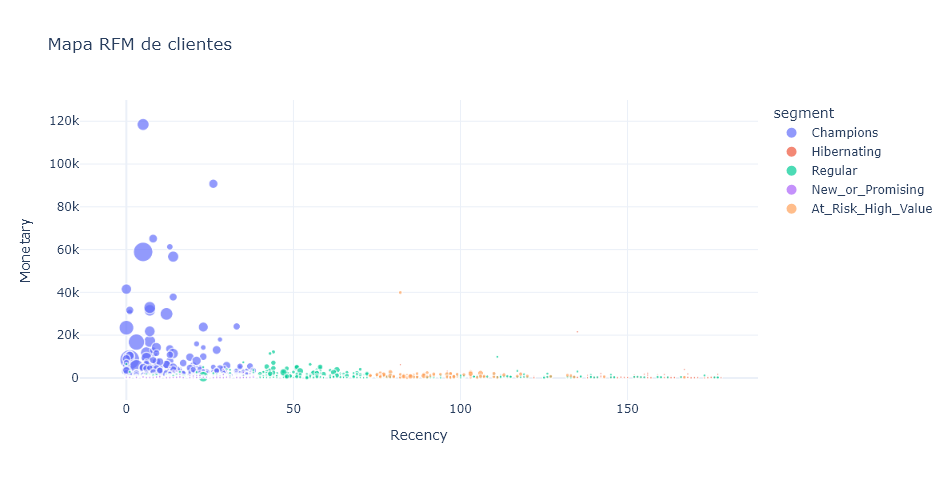

In [11]:
fig = px.scatter(
    rfm,
    x="Recency",
    y="Monetary",
    size="Frequency",
    color="segment",
    hover_data=["CustomerID","churn"],
    title="Mapa RFM de clientes"
)
fig.show()

# 7. Proxy de CLV para priorización económica

### Qué hace esta celda: Extrapolación de ingresos a doce meses

Calcula el ticket promedio multiplicado por la frecuencia mensual y por doce. Como ticket por frecuencia equivale a Monetary, esta aproximación es proporcional a las ventas históricas. Es una referencia de ingresos en libras para decidir y no una estimación completa de rentabilidad de vida del cliente.

In [12]:
# Proxy didáctico: ticket medio × frecuencia mensual × 12; proxy de ingresos, no CLV completo
months_obs = obs_days / 30.4375
rfm["freq_monthly"] = rfm["Frequency"] / months_obs
rfm["CLV_proxy_12m"] = rfm["avg_ticket"] * rfm["freq_monthly"] * 12

display(
    rfm[["CustomerID","avg_ticket","Frequency","CLV_proxy_12m","segment","churn"]]
      .sort_values("CLV_proxy_12m", ascending=False)
      .head(10)
)

,CustomerID,avg_ticket,Frequency,CLV_proxy_12m,segment,churn
1100,14646.0,3949.664000,30,240435.796000,Champions,0
2683,18102.0,4777.428421,19,184189.771583,Champions,0
2391,17450.0,3830.664706,17,132141.971250,Champions,0
35,12415.0,6811.491111,9,124394.856417,Champions,0
1227,14911.0,727.320494,81,119544.214667,Champions,0
862,14156.0,2100.314815,27,115070.997917,Champions,0
2622,17949.0,1729.379167,24,84220.765417,Champions,0
1315,15098.0,13305.500000,3,80997.231250,At_Risk_High_Value,1
2412,17511.0,2701.329286,14,76740.262792,Champions,0
1731,16029.0,1062.418387,31,66830.543292,Champions,0


> **Advertencia metodológica:** `CLV_proxy_12m` es una aproximación para el ejercicio de decisión. Es una extrapolación de ingresos históricos a 12 meses. No incorpora margen individual, supervivencia, tasa de descuento ni costos futuros. Se conserva CLV_proxy_12m como nombre operativo. Este horizonte económico difiere de los 90 días usados para churn.

### Pregunta 3
¿Por qué dos clientes con la misma probabilidad de churn podrían recibir decisiones distintas si sus valores económicos son diferentes?

**Respuesta:** La probabilidad mide riesgo, no cuánto se recuperaría. Con los supuestos del caso, el valor esperado previo al contacto de un cliente sería `p × 0,25 × (0,30 × proxy − 15) − 5`. A igual riesgo del 50 %, un proxy de £1.000 produce £30,625 esperados y uno de £100 produce −£3,125. El primero justificaría el contacto y el segundo no bajo esa regla individual. Son ejemplos calculados para explicar la fórmula, no resultados de clientes reales; la política base del laboratorio compara umbrales globales.

# 8. Modelo de churn con scikit-learn

### Qué hace esta celda: Entrenamiento y partición independiente

Divide los 2.772 clientes en entrenamiento, validación y prueba aproximadamente 60/20/20, estratificando por churn. Un pipeline ajusta StandardScaler y regresión logística solamente con entrenamiento. La validación selecciona la política y la prueba estima su desempeño sin reajustar el umbral. La separación es entre clientes de un mismo corte: no demuestra generalización a otros periodos.

In [13]:
# CLV_proxy_12m es proporcional a Monetary: se conserva para la decisión,
# pero no se duplica como predictor del modelo.
features = ["Recency", "Frequency", "Monetary", "Products", "Lines", "avg_ticket"]
model_df = rfm.dropna(subset=features + ["churn"]).copy()
X = model_df[features]
y = model_df["churn"]
idx_train, idx_hold = train_test_split(model_df.index, test_size=0.40,
    random_state=RANDOM_STATE, stratify=y)
idx_val, idx_test = train_test_split(idx_hold, test_size=0.50,
    random_state=RANDOM_STATE, stratify=y.loc[idx_hold])
X_train, y_train = X.loc[idx_train], y.loc[idx_train]
X_val, y_val = X.loc[idx_val], y.loc[idx_val]
X_test, y_test = X.loc[idx_test], y.loc[idx_test]
pipe = Pipeline([("scale", StandardScaler()),
                 ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
pipe.fit(X_train, y_train)
proba_val = pipe.predict_proba(X_val)[:, 1]
proba = pipe.predict_proba(X_test)[:, 1]
print("Clientes entrenamiento / validación / prueba:", len(idx_train), len(idx_val), len(idx_test))
print("ROC-AUC en prueba:", round(roc_auc_score(y_test, proba), 4))
print("Average Precision (AP) en prueba:", round(average_precision_score(y_test, proba), 4))
print("El umbral se selecciona solo en validación. La prueba no se usa para reajustarlo.")


Clientes entrenamiento / validación / prueba: 1663 554 555
ROC-AUC en prueba: 0.7255
Average Precision (AP) en prueba: 0.5926
El umbral se selecciona solo en validación. La prueba no se usa para reajustarlo.


### Qué hace esta celda: Clasificación con umbral de referencia 0,50

Convierte probabilidades en clases al superar o igualar 0,50. El reporte y la matriz de confusión muestran aciertos y errores de clasificación en prueba. Este umbral sirve como referencia predictiva y puede diferir del umbral que maximiza valor económico.

In [14]:
# Evaluación inicial con umbral 0.50 SOLO como referencia
pred_050 = (proba >= 0.50).astype(int)

print(classification_report(y_test, pred_050, digits=4))
print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_050))

              precision    recall  f1-score   support

           0     0.7181    0.7181    0.7181       337
           1     0.5642    0.5642    0.5642       218

    accuracy                         0.6577       555
   macro avg     0.6412    0.6412    0.6412       555
weighted avg     0.6577    0.6577    0.6577       555

Matriz de confusión:
[[242  95]
 [ 95 123]]


### Qué hace esta celda: Capacidad de ordenar clientes por riesgo

Traza ROC y precision-recall con las probabilidades de prueba, sin cambiar el modelo. ROC-AUC mide discriminación y Average Precision resume la recuperación de positivos. La línea base de AP es la prevalencia de churn; ninguna de estas métricas acredita una respuesta causal al contacto.

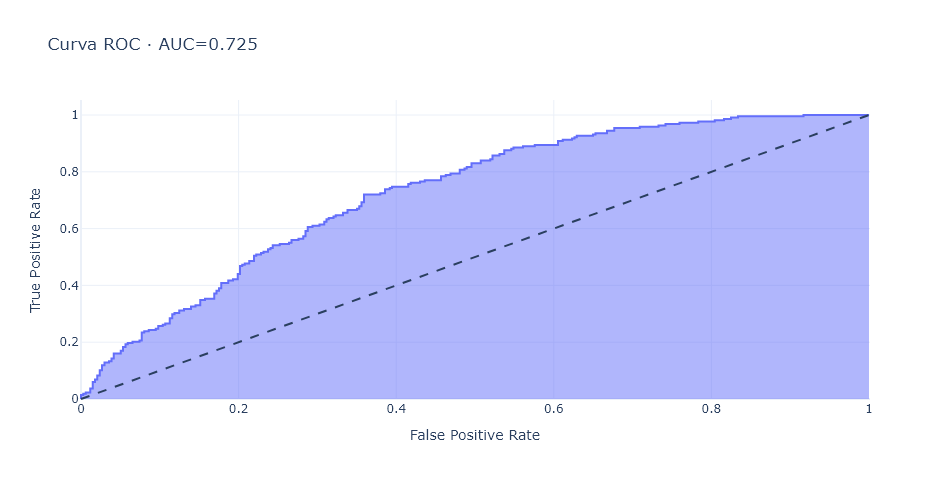

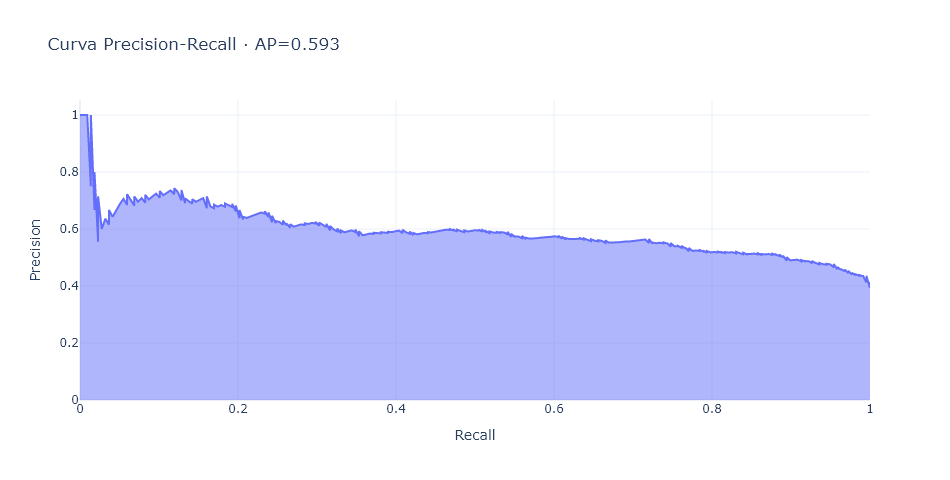

In [15]:
fpr, tpr, _ = roc_curve(y_test, proba)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, proba)

fig_roc = px.area(
    x=fpr, y=tpr,
    title=f"Curva ROC · AUC={roc_auc_score(y_test, proba):.3f}",
    labels={"x":"False Positive Rate","y":"True Positive Rate"}
)
fig_roc.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line_dash="dash")
fig_roc.show()

fig_pr = px.area(
    x=recall_curve, y=precision_curve,
    title=f"Curva Precision-Recall · AP={average_precision_score(y_test, proba):.3f}",
    labels={"x":"Recall","y":"Precision"}
)
fig_pr.show()

### Pregunta 4
¿Qué métrica utilizaría para comparar modelos si churn fuera minoritario: accuracy, ROC-AUC o AP? Justifique según el costo de perder clientes en riesgo.

**Respuesta:** Priorizaría AP al comparar modelos cuando churn es minoritario, porque resume precisión y recall de la clase que buscamos y permite contrastar con su prevalencia. Accuracy podría ser alta prediciendo que nadie abandona; ROC-AUC aporta discriminación, pero puede ocultar baja precisión con muchos negativos. En prueba, AP es 0,5926 frente a una prevalencia de 0,3928 y ROC-AUC es 0,7255. Para decidir la campaña revisaría además el valor económico y el coste de omitir clientes valiosos: AP no define por sí sola la política rentable.

# 9. Del score al umbral de decisión

### Qué hace esta celda: Tablas para evaluar las decisiones

Vincula cada cliente de validación y prueba con su segmento, proxy económico, etiqueta y probabilidad. CustomerID identifica registros, pero no se utiliza como predictor. La etiqueta se emplea solo para simular retrospectivamente el resultado, nunca para decidir a quién contactar.

In [16]:
cols = ["CustomerID", "segment", "CLV_proxy_12m", "churn"]
val_result = model_df.loc[idx_val, cols].copy()
val_result["proba_churn"] = proba_val
test_result = model_df.loc[idx_test, cols].copy()
test_result["proba_churn"] = proba
display(val_result.head())


,CustomerID,segment,CLV_proxy_12m,churn,proba_churn
1213,14880.0,Hibernating,474.967042,0,0.557962
1419,15304.0,Regular,534.279583,0,0.277227
1944,16473.0,Regular,199.467083,1,0.552662
1258,14984.0,Hibernating,223.573583,0,0.550544
2394,17455.0,Hibernating,267.241250,1,0.595149


## Supuestos económicos del caso

Estos valores **no provienen de UCI**. Son supuestos explícitos para convertir el score en una decisión:

- costo de contacto: **£5** por cliente contactado;
- incentivo: **£15** por verdadero churn que se supone retenido gracias a la intervención;
- efectividad de retención: **25 %**;
- margen recuperable: **30 % del CLV proxy**.

Se evaluarán múltiples umbrales.

El valor es una simulación retrospectiva bajo supuestos, no una ganancia observada ni un efecto causal probado. La evaluación se refiere únicamente al subconjunto indicado. Una campaña real requiere verificar el efecto incremental y validar en otros periodos.


### Qué hace esta celda: Simulación económica de los umbrales

Compara políticas de contacto con coste £5, incentivo £15, retención supuesta del 25 % y margen recuperable del 30 %. El valor simulado es `0,25 × 0,30 × suma(proxy de churn contactados) − 5 × contactos − 0,25 × 15 × verdaderos positivos`. Solo los churn contactados aportan valor recuperado supuesto; todos los contactos generan coste. Incluye contactar a todos y no contactar como referencias.

In [17]:
CONTACT_COST = 5.0
INCENTIVE = 15.0
RETENTION_RATE = 0.25
RECOVERABLE_MARGIN = 0.30

def evaluate_threshold(data, threshold,
                       retention_rate=RETENTION_RATE,
                       contact_cost=CONTACT_COST,
                       incentive=INCENTIVE,
                       recoverable_margin=RECOVERABLE_MARGIN):

    d = data.copy()
    d["contact"] = (d["proba_churn"] >= threshold).astype(int)

    tp_mask = (d["contact"] == 1) & (d["churn"] == 1)

    contacted = int(d["contact"].sum())
    tp = int(tp_mask.sum())
    fp = int(((d["contact"] == 1) & (d["churn"] == 0)).sum())
    fn = int(((d["contact"] == 0) & (d["churn"] == 1)).sum())

    precision = tp / contacted if contacted else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    contact_total = contacted * contact_cost
    expected_retained = tp * retention_rate
    incentive_total = expected_retained * incentive

    recovered_value = (
        d.loc[tp_mask, "CLV_proxy_12m"].sum()
        * retention_rate
        * recoverable_margin
    )

    net_value = recovered_value - contact_total - incentive_total

    return {
        "threshold": threshold,
        "policy": "No contactar" if threshold > 1 else ("Contactar a todos" if threshold == 0 else f"Umbral {threshold:.2f}"),
        "contacted": contacted,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "recovered_value": recovered_value,
        "contact_cost": contact_total,
        "incentive_cost": incentive_total,
        "net_value": net_value
    }

thresholds = np.r_[0.0, np.round(np.arange(0.10, 0.91, 0.05), 2), 1.01]
# 0.0 contacta a todos; 1.01 representa no contactar a nadie.

economic = pd.DataFrame([
    evaluate_threshold(val_result, t)
    for t in thresholds
])

display(economic)

,threshold,policy,contacted,TP,FP,FN,precision,recall,recovered_value,contact_cost,incentive_cost,net_value
0,0.00,Contactar a todos,554,218,336,0,0.393502,1.000000,23488.781591,2770.0,817.50,19901.281591
1,0.10,Umbral 0.10,491,213,278,5,0.433809,0.977064,21584.199163,2455.0,798.75,18330.449163
2,0.15,Umbral 0.15,467,209,258,9,0.447537,0.958716,20471.384378,2335.0,783.75,17352.634378
3,0.20,Umbral 0.20,434,199,235,19,0.458525,0.912844,18362.875266,2170.0,746.25,15446.625266
4,0.25,Umbral 0.25,415,196,219,22,0.472289,0.899083,12010.999706,2075.0,735.00,9200.999706
5,0.30,Umbral 0.30,387,188,199,30,0.485788,0.862385,10985.510109,1935.0,705.00,8345.510109
6,0.35,Umbral 0.35,352,172,180,46,0.488636,0.788991,9208.669303,1760.0,645.00,6803.669303
7,0.40,Umbral 0.40,297,157,140,61,0.528620,0.720183,8157.087159,1485.0,588.75,6083.337159
8,0.45,Umbral 0.45,260,143,117,75,0.550000,0.655963,6794.325713,1300.0,536.25,4958.075713
9,0.50,Umbral 0.50,207,116,91,102,0.560386,0.532110,5570.818872,1035.0,435.00,4100.818872


### Qué hace esta celda: Selección en validación y aplicación en prueba

Elige el mayor valor neto entre las políticas evaluadas; en empate prefiere menos contactos y luego mayor umbral. Fija esta decisión y la aplica al conjunto de prueba sin optimizarla de nuevo. La tabla permite verificar valor recuperable y costes por separado.

In [18]:
# Desempate: preferir menos contactos, luego mayor umbral.
def choose_policy(table):
    return table.sort_values(["net_value", "contacted", "threshold"],
                             ascending=[False, True, False]).iloc[0]
best = choose_policy(economic)
final_result = evaluate_threshold(test_result, float(best["threshold"]))
print("MEJOR POLÍTICA ENTRE LAS EVALUADAS EN VALIDACIÓN")
print(best.to_string())
print("EVALUACIÓN EN PRUEBA SIN REAJUSTAR EL UMBRAL")
display(pd.DataFrame([final_result]))


MEJOR POLÍTICA ENTRE LAS EVALUADAS EN VALIDACIÓN
threshold                        0.0
policy             Contactar a todos
contacted                        554
TP                               218
FP                               336
FN                                 0
precision                   0.393502
recall                           1.0
recovered_value         23488.781591
contact_cost                  2770.0
incentive_cost                 817.5
net_value               19901.281591
EVALUACIÓN EN PRUEBA SIN REAJUSTAR EL UMBRAL


,threshold,policy,contacted,TP,FP,FN,precision,recall,recovered_value,contact_cost,incentive_cost,net_value
0,0.0,Contactar a todos,555,218,337,0,0.392793,1.0,15381.579972,2775.0,817.5,11789.079972


### Qué hace esta celda: Valor económico frente al umbral

Grafica el valor neto simulado exclusivamente en validación y señala el umbral seleccionado. El valor 1,01 codifica no contactar a nadie; la optimización se limita a esta grilla y a estos supuestos.

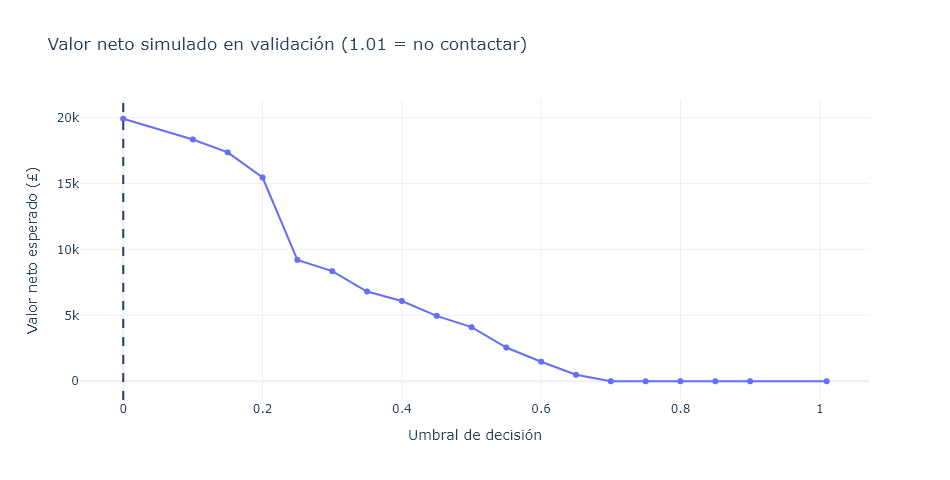

In [19]:
fig = px.line(
    economic,
    x="threshold",
    y="net_value",
    markers=True,
    title="Valor neto simulado en validación (1.01 = no contactar)",
    labels={
        "threshold":"Umbral de decisión",
        "net_value":"Valor neto esperado (£)"
    }
)
fig.add_vline(x=float(best["threshold"]), line_dash="dash")
fig.show()

### Qué hace esta celda: Precisión y cobertura de la política

Compara precisión y recall de las políticas en validación. Contactar a todos cubre todos los churn observados, pero también incluye clientes que volverían a comprar. Recall del 100 % no significa retención del 100 % ni una campaña perfectamente eficaz.

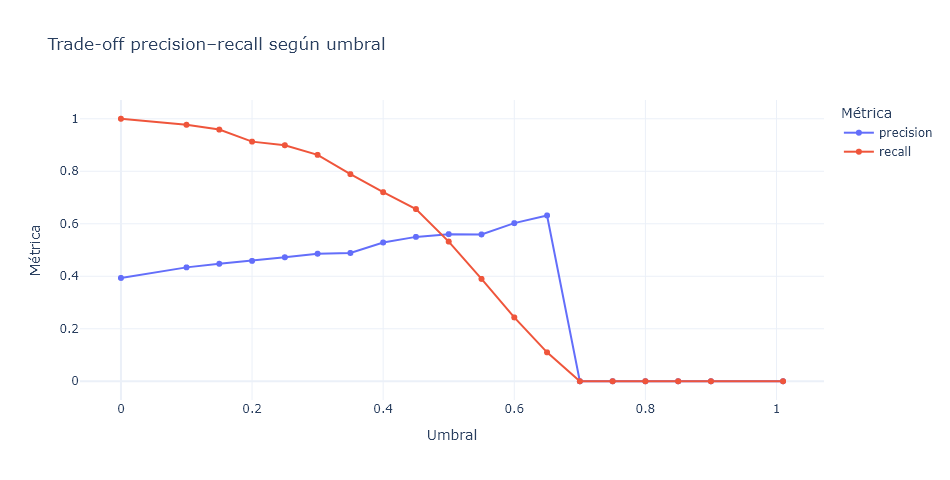

In [20]:
fig = px.line(
    economic,
    x="threshold",
    y=["precision","recall"],
    markers=True,
    title="Trade-off precision–recall según umbral",
    labels={"threshold":"Umbral","value":"Métrica","variable":"Métrica"}
)
fig.show()

### Pregunta 5
¿La política elegida en validación coincide con el umbral 0,50?

**Respuesta:** No. Gana el umbral 0,00, que contacta a los 554 clientes de validación y alcanza £19.901,28 netos simulados. El umbral 0,50 contacta a 207 clientes y obtiene £4.100,82. Una precisión mayor no compensa el valor recuperable perdido al excluir clientes: la diferencia es £15.800,46 a favor del contacto general. Esta es la mejor política entre las evaluadas y bajo los supuestos, no un óptimo universal.

### Pregunta 6
¿Cuántos clientes se contactarían en prueba y cuál es su valor simulado?

**Respuesta:** Al mantener la política seleccionada se contactaría a los 555 clientes de prueba, de los cuales 218 presentan churn observado. El valor recuperado supuesto es £15.381,58, menos £2.775,00 de contactos y £817,50 de incentivos: valor neto simulado de £11.789,08 frente a £0 por no contactar. La precisión es 39,28 % y el recall 100 %; no significa retener al 100 %. La efectividad del 25 % equivale a 54,5 clientes retenidos esperados en la simulación, no a un conteo observado. No extrapolo este importe a los 2.772 clientes modelados.


# 10. Sensibilidad económica

### Qué hace esta celda: Sensibilidad a la efectividad supuesta

Repite la selección de umbral en validación para efectividades de 10 %, 25 % y 40 %, manteniendo los demás supuestos. Aplica cada política seleccionada a prueba como análisis de sensibilidad predefinido; no utiliza la prueba para escoger el escenario favorable.

In [21]:
scenarios = []
for retention_rate in [0.10, 0.25, 0.40]:
    temp = pd.DataFrame([evaluate_threshold(val_result, t, retention_rate=retention_rate)
                         for t in thresholds])
    selected = choose_policy(temp)
    row = evaluate_threshold(test_result, float(selected["threshold"]), retention_rate=retention_rate)
    row["retention_rate"] = retention_rate
    row["validation_net_value"] = float(selected["net_value"])
    scenarios.append(row)
scenario_df = pd.DataFrame(scenarios)
display(scenario_df[["retention_rate", "policy", "contacted", "precision", "recall", "net_value"]])


,retention_rate,policy,contacted,precision,recall,net_value
0,0.10,Contactar a todos,555,0.392793,1.0,3050.631989
1,0.25,Contactar a todos,555,0.392793,1.0,11789.079972
2,0.40,Contactar a todos,555,0.392793,1.0,20527.527955


### Qué hace esta celda: Comparación económica de escenarios

Muestra cómo cambia el valor neto en prueba al cambiar la efectividad asumida. Aunque la política elegida permanezca igual, su rentabilidad simulada puede cambiar mucho; la efectividad real todavía debe medirse.

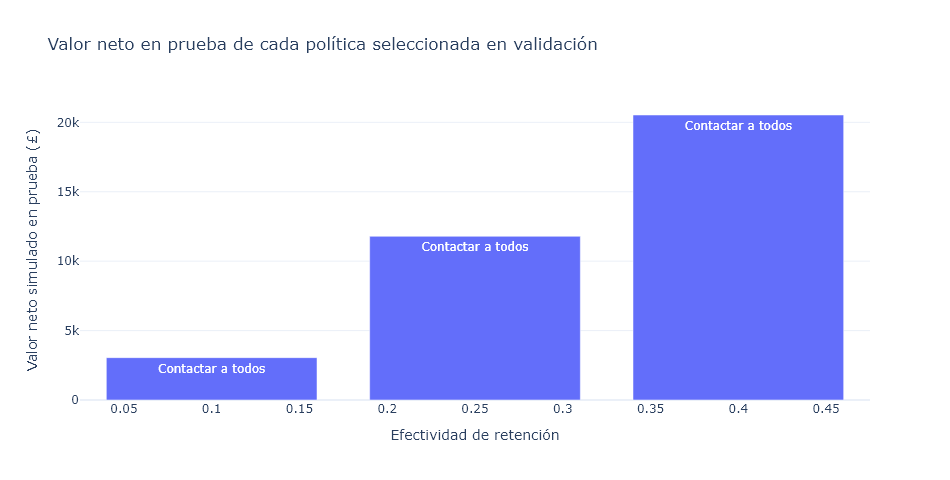

In [22]:
fig = px.bar(
    scenario_df,
    x="retention_rate",
    y="net_value",
    text="policy",
    title="Valor neto en prueba de cada política seleccionada en validación",
    labels={
        "retention_rate":"Efectividad de retención",
        "net_value":"Valor neto simulado en prueba (£)",
        "threshold":"Umbral óptimo"
    }
)
fig.show()

### Pregunta 7
Al comparar efectividades de 10 %, 25 % y 40 %, ¿cambian la política elegida, los clientes contactados y el valor neto en prueba? Explique qué enseña esto sobre predicción y decisión.

**Respuesta:** No cambian la política ni los contactos: con efectividades de 10 %, 25 % y 40 % se selecciona contactar a todos y se contactaría a 555 clientes en prueba. Sí cambia el valor neto simulado: £3.050,63; £11.789,08 y £20.527,53, respectivamente. Las probabilidades del modelo permanecen iguales; cambian los supuestos económicos. La recomendación se mantiene dentro de estos tres escenarios, pero eso no demuestra que sea robusta ante cualquier efectividad ni que la tasa real sea del 25 %.

# 11. Priorización por segmento RFM

### Qué hace esta celda: Riesgo, valor y contribución por segmento

Resume cantidad de clientes, riesgo observado, probabilidad media y proxy económico de prueba. Añade el valor neto simulado de la política fija para cada segmento y un indicador previo al contacto que combina probabilidad y valor. Los resultados observados ayudan a interpretar, pero no sirven para rediseñar la política usando prueba.

In [23]:
segment_econ = (
    test_result.groupby("segment")
               .agg(
                   clientes=("CustomerID","nunique"),
                   churn_rate=("churn","mean"),
                   proba_media=("proba_churn","mean"),
                   clv_medio=("CLV_proxy_12m","mean"),
                   clv_total=("CLV_proxy_12m","sum")
               )
               .sort_values("clv_total", ascending=False)
)

display(segment_econ)
# Evaluación descriptiva de la política ya fijada, sin volver a seleccionarla.
segment_values = {
    name: evaluate_threshold(group, float(best["threshold"]))["net_value"]
    for name, group in test_result.groupby("segment")
}
segment_econ["neto_simulado_GBP"] = pd.Series(segment_values)
test_result["valor_esperado_contacto"] = (
    test_result["proba_churn"] * RETENTION_RATE
    * (RECOVERABLE_MARGIN * test_result["CLV_proxy_12m"] - INCENTIVE)
    - CONTACT_COST
)
segment_econ["valor_esperado_medio_GBP"] = test_result.groupby("segment")["valor_esperado_contacto"].mean()
display(segment_econ.round(2))
assert np.isclose(segment_econ["neto_simulado_GBP"].sum(), final_result["net_value"])


,clientes,churn_rate,proba_media,clv_medio,clv_total
segment,,,,,
Champions,113,0.115044,0.095179,9163.556129,1.035482e+06
Regular,218,0.389908,0.369099,1557.564598,3.395491e+05
Hibernating,161,0.577640,0.600383,782.900771,1.260470e+05
At_Risk_High_Value,20,0.100000,0.264459,2161.276577,4.322553e+04
New_or_Promising,43,0.581395,0.472799,756.134557,3.251379e+04


,clientes,churn_rate,proba_media,clv_medio,clv_total,neto_simulado_GBP,valor_esperado_medio_GBP
segment,,,,,,,
Champions,113,0.12,0.10,9163.56,1035481.84,2305.21,17.88
Regular,218,0.39,0.37,1557.56,339549.08,5246.65,27.47
Hibernating,161,0.58,0.60,782.90,126047.02,3150.16,27.87
At_Risk_High_Value,20,0.10,0.26,2161.28,43225.53,261.00,29.11
New_or_Promising,43,0.58,0.47,756.13,32513.79,826.06,16.36


### Preguntas 8 y 9 — Resueltas en el cierre ejecutivo
8. Se prioriza el segmento combinando su riesgo y valor, y se distingue la priorización operativa de una nueva política no validada.
9. Se explicita una limitación y una condición de cambio en el cierre único que sigue.


# 12. Informe ejecutivo

### Qué hace esta celda: Comprobación y síntesis de resultados

Verifica ausencia de solapamiento entre particiones, cobertura temporal y finitud de predicciones. Imprime los resultados que sustentan las respuestas y el cierre. Estas comprobaciones detectan fallos de ejecución; no sustituyen una validación temporal ni un experimento de campaña.

In [24]:
assert set(idx_train).isdisjoint(idx_val)
assert set(idx_train).isdisjoint(idx_test)
assert set(idx_val).isdisjoint(idx_test)
assert len(idx_train) + len(idx_val) + len(idx_test) == len(model_df)
assert model_df["CustomerID"].is_unique
assert hist["InvoiceDate"].ge(obs_start).all() and hist["InvoiceDate"].lt(cutoff).all()
assert future["InvoiceDate"].ge(cutoff).all() and future["InvoiceDate"].lt(target_end).all()
assert np.isfinite(proba).all() and np.isfinite(proba_val).all()
assert np.isclose(final_result["net_value"], final_result["recovered_value"] - final_result["contact_cost"] - final_result["incentive_cost"])
print("Comprobaciones de consistencia: OK")
best_threshold = float(best["threshold"])
best_contacted = int(final_result["contacted"])
best_value = float(final_result["net_value"])

print("Resumen automático para apoyar la redacción")
print("-------------------------------------------")
print("Clientes modelados:", len(model_df))
print("Tasa churn:", f"{model_df['churn'].mean():.2%}")
print("ROC-AUC:", f"{roc_auc_score(y_test, proba):.4f}")
print("AP:", f"{average_precision_score(y_test, proba):.4f}")
print("Política elegida en validación:", best["policy"])
print("Clientes evaluados en prueba:", len(test_result))
print("Clientes a contactar:", best_contacted)
print("Valor neto simulado en prueba (£):", f"{best_value:,.2f}")
print("Precision:", f"{final_result['precision']:.2%}")
print("Recall:", f"{final_result['recall']:.2%}")

Comprobaciones de consistencia: OK
Resumen automático para apoyar la redacción
-------------------------------------------
Clientes modelados: 2772
Tasa churn: 39.29%
ROC-AUC: 0.7255
AP: 0.5926
Política elegida en validación: Contactar a todos
Clientes evaluados en prueba: 555
Clientes a contactar: 555
Valor neto simulado en prueba (£): 11,789.08
Precision: 39.28%
Recall: 100.00%


### Informe ejecutivo — 8 líneas
1. Churn significa no comprar durante 90 días después del corte 01/09/2011; las variables usan los 180 días anteriores.
2. Se modelaron 2.772 clientes, con churn de 39,29 %; prueba incluye 555 clientes.
3. En prueba, ROC-AUC = 0,7255 y AP = 0,5926; con umbral 0,50, la matriz es TN=242, FP=95, FN=95 y TP=123.
4. En validación gana contactar a todos (umbral 0,00), con £19.901,28 de valor neto simulado entre las políticas evaluadas.
5. Aplicada sin reajuste, contactaría a 555 clientes de prueba, con precisión de 39,28 % y recall de 100 %.
6. El neto simulado en prueba es £11.789,08 frente a £0 por no contactar, asumiendo coste £5, incentivo £15, efectividad 25 % y margen 30 %.
7. Para ordenar contactos combinaría riesgo y valor: Regular aporta £5.246,65 netos simulados (218 clientes; churn 38,99 %; proxy medio £1.557,56) y Hibernating £3.150,16 (churn 57,76 %); no descartaría otros segmentos ni afirmaría haber validado una campaña restringida.
8. El proxy extrapola ingresos y no demuestra causalidad; cambiaría la decisión si un piloto con control muestra valor incremental neto no positivo o si costes y efectividad reales alteran la selección en una nueva validación.


# 13. Cierre oral
Recomiendo evaluar en un piloto la política de contactar a todos porque el valor neto simulado en prueba es £11.789,08 bajo los supuestos del caso. Mantendría un grupo de control aleatorio y mediría retención a 90 días, coste por cliente retenido incremental y margen incremental neto. Cambiaría la decisión si el efecto real o los costes dejan de justificar la intervención.


# 14. Evidencia de entrega y uso de IA

- [x] Fuente UCI, ID 502, fecha de ejecución y huella del archivo visibles.
- [x] Limpieza y tratamiento de duplicados documentados.
- [x] Features históricas y etiqueta futura separadas; particiones sin clientes compartidos.
- [x] RFM, proxy de ingresos y sus limitaciones explicados.
- [x] Modelo ejecutado, ROC-AUC, AP, matriz y gráficos visibles.
- [x] Selección en validación, evaluación en prueba y sensibilidad económica.
- [x] Preguntas 1–9 resueltas y cierre ejecutivo cuantificado.

**Limitaciones adicionales:** se usa un solo corte temporal, no hay intervención real ni etiquetas de respuesta al tratamiento y la exclusión de compras sin ID puede sesgar la cohorte identificada. Se asume estabilidad de compras, margen uniforme y efectividad homogénea. La segmentación es descriptiva; un despliegue requeriría fijar sus reglas con datos históricos de referencia. No se verifica causalidad ni calibración de probabilidades, por lo que el indicador de valor esperado individual es orientativo.

**Uso de IA:** se utilizó OpenAI Codex para apoyar la revisión del código, la documentación, las respuestas y las comprobaciones de ejecución. El notebook distingue cifras calculadas, ejemplos hipotéticos y supuestos; no se realizó una campaña real.


# Referencias
- Chen, D. (2012). *Online Retail II* [Dataset], UCI, ID 502. [Fuente y licencia CC BY 4.0](https://archive.ics.uci.edu/dataset/502/online+retail+ii). [DOI: 10.24432/C5CG6D](https://doi.org/10.24432/C5CG6D).
- Provost, F., & Fawcett, T. *Data Science for Business*.
- Kelleher, J. D., Mac Namee, B., & D’Arcy, A. *Fundamentals of Machine Learning for Predictive Data Analytics*.
